Привет! 

Ниже изложена работа с данными в линейном порядке, в котором я шла по заданию.
Сначала идут мои попытки знакомства с данными, некоторый feature engineering, графики и затем уже обучение модели.

In [433]:
import numpy as np
import pandas as pd
import re

import lightgbm as lgb
from metric import precision_at_recall, recall_at_fpr

RANDOM_SEED = 42

In [434]:
train = pd.read_csv('data/train.csv', parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])
events = pd.read_csv('data/events.csv.gz', parse_dates=['event_ts'])
test = pd.read_csv('data/test.csv', parse_dates=['cookie_created_at', 'window_start_ts', 'window_end_ts'])

print(train.shape, test.shape, events.shape)
print('доля ботов в train:', train.target.mean().round(4))
train.head()

(11091, 5) (4909, 4) (328905, 14)
доля ботов в train: 0.0811


,cookie_id,cookie_created_at,window_start_ts,window_end_ts,target
0,ck_54a059eb7d3ea68b,2025-11-21 09:30:41,2026-04-06,2026-04-07,0
1,ck_7e4de46eeab82974,2025-09-23 10:10:24,2026-04-06,2026-04-07,0
2,ck_9320229ef6304522,2026-03-04 00:08:02,2026-04-06,2026-04-07,0
3,ck_30ccd25bc1714ed9,2026-04-05 10:52:40,2026-04-06,2026-04-07,0
4,ck_a77c5f05948cdeef,2026-01-01 03:54:35,2026-04-06,2026-04-07,0


---
# Этап пристального взгляда на данные и предобработки 
Разберемся, с какими данными вообще имеем дело.

In [435]:
train.info()
test.info()
print('Количество дублей train', train.duplicated().sum())
print('Количество дублей tets', test.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 11091 entries, 0 to 11090
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   cookie_id          11091 non-null  str           
 1   cookie_created_at  11091 non-null  datetime64[us]
 2   window_start_ts    11091 non-null  datetime64[us]
 3   window_end_ts      11091 non-null  datetime64[us]
 4   target             11091 non-null  int64         
dtypes: datetime64[us](3), int64(1), str(1)
memory usage: 433.4 KB
<class 'pandas.DataFrame'>
RangeIndex: 4909 entries, 0 to 4908
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   cookie_id          4909 non-null   str           
 1   cookie_created_at  4909 non-null   datetime64[us]
 2   window_start_ts    4909 non-null   datetime64[us]
 3   window_end_ts      4909 non-null   datetime64[us]
dtypes: datetime64[us](3),

Пропусков и дубликатов в трейне и тесте нет

---

In [436]:
events.info()

<class 'pandas.DataFrame'>
RangeIndex: 328905 entries, 0 to 328904
Data columns (total 14 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   cookie_id      328905 non-null  str           
 1   event_ts       328905 non-null  datetime64[us]
 2   eid            328905 non-null  int64         
 3   event_name     328905 non-null  str           
 4   platform       328905 non-null  str           
 5   user_agent     328905 non-null  str           
 6   item_id        214308 non-null  float64       
 7   item_category  295985 non-null  str           
 8   item_location  305112 non-null  str           
 9   seller_type    195052 non-null  str           
 10  search_query   100402 non-null  str           
 11  search_page    100402 non-null  float64       
 12  pointer_x      108540 non-null  float64       
 13  pointer_y      108540 non-null  float64       
dtypes: datetime64[us](1), float64(4), int64(1), str(8)
memory usage

In [437]:
events = events.drop_duplicates()
print(events.shape)

(324042, 14)


Дубликаты из events были убраны, с NaN будем разбираться позднее. Важно, что cookie_id, event_ts, event_name пустых значений не имеют

---

Посмотрим, какие типы событий есть и на статистики столбцов events с помощью describe

In [438]:
print(events['event_name'].value_counts().to_string())

event_name
item_view               118990
search_results_view      98929
photo_swipe              35962
favorite_add             18739
seller_page_view         17180
contact_phone_show       11154
captcha_shown             7831
login                     6178
contact_chat_open         6047
contact_message_sent      3032


In [439]:
events.describe(include="all")

,cookie_id,event_ts,eid,event_name,platform,user_agent,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y
count,324042,324042,324042.000000,324042,324042,324042,2.111040e+05,291584,300574,192154,98929,98929.000000,106966.000000,106966.000000
unique,16000,NaN,NaN,10,11,148,NaN,15,40,2,120,NaN,NaN,NaN
top,ck_bd32dd3b2cbb7888,NaN,NaN,item_view,desktop,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,NaN,avtomobili,sankt-peterburg,private,кофемашина,NaN,NaN,NaN
freq,187,NaN,NaN,118990,46157,3688,NaN,20536,38579,110955,907,NaN,NaN,NaN
mean,NaN,2026-04-15 20:42:22.213114,212.133190,NaN,NaN,NaN,1.029992e+06,NaN,NaN,NaN,NaN,2.902395,913.377101,535.585326
min,NaN,2026-04-06 00:02:57,100.000000,NaN,NaN,NaN,1.000000e+06,NaN,NaN,NaN,NaN,1.000000,0.000000,0.000000
25%,NaN,2026-04-10 18:38:16.250000,100.000000,NaN,NaN,NaN,1.014983e+06,NaN,NaN,NaN,NaN,1.000000,458.000000,282.000000
50%,NaN,2026-04-15 03:39:48.500000,200.000000,NaN,NaN,NaN,1.030038e+06,NaN,NaN,NaN,NaN,2.000000,884.000000,533.000000
75%,NaN,2026-04-20 17:07:22.750000,210.000000,NaN,NaN,NaN,1.044955e+06,NaN,NaN,NaN,NaN,4.000000,1358.000000,789.000000
max,NaN,2026-04-26 23:59:50,900.000000,NaN,NaN,NaN,1.059999e+06,NaN,NaN,NaN,NaN,65.000000,1920.000000,1080.000000


Из прям интересного в глаза бросается максимальная страница поиска, равная 65. Стоит обратить внимание, человек ну прям вряд ли дальше 10-15 страницы пойдет, и то это прям надо сильно заскучать

In [440]:
print(events['event_name'].value_counts().to_string(), '\n')
print(events['platform'].value_counts().to_string())

event_name
item_view               118990
search_results_view      98929
photo_swipe              35962
favorite_add             18739
seller_page_view         17180
contact_phone_show       11154
captcha_shown             7831
login                     6178
contact_chat_open         6047
contact_message_sent      3032 

platform
desktop    46157
WEB        45799
Web        45703
web        45284
ANDROID    41809
Android    41637
android    41542
iOS         4035
iphone      4035
IOS         4028
ios         4013


In [441]:
#приведем платформы к нижнему регистру
events["platform"] = events["platform"].astype("string").str.strip().str.lower()

events = events.drop(columns=['eid']) #выкинула eid (потому что техинфа)

---
Разберемся, что происходит со столбцом User-agent. 

Попросила дать нейронку примеры маркеров внутри UA, которые  могут указывать на бота. Это не стопроцентное свидетельство о "нечеловеке" (user-agent можно подделать), но может послужить признаком. Сам весь User-agent нет смысла отдавать модели для обучения.




In [442]:
# Список подстрок-маркеров
bot_markers = [
    'bot', 'python', 'go-http-client', 'curl', 'wget',
    'java', 'scrapy', 'requests', 'aiohttp', 'httpx',
    'libwww-perl', 'phantomjs', 'headlesschrome', 'selenium',
    'puppeteer', 'playwright', 'httpclient', 'axios', 'node-fetch'
]

ua = events['user_agent'].dropna().unique()
ua_df = pd.DataFrame({'user_agent': ua})

pattern = '|'.join(map(re.escape, bot_markers))
ua_df['ua_marker'] = (
    ua_df['user_agent'].str.lower()
    .str.extract(f'({pattern})', expand=False)
    .fillna('none')
)
events = events.merge(ua_df, on='user_agent', how='left')
events['ua_marker'].value_counts()

ua_marker
none              304792
headlesschrome     12270
python              2141
node-fetch          1275
curl                1195
scrapy              1190
go-http-client      1179
Name: count, dtype: int64

In [443]:
# проверим, бывают ли одни и те же куки с разными ua
cookies_with_different_ua = (
    events.groupby("cookie_id")["user_agent"]
      .nunique(dropna=True)
      .loc[lambda s: s > 1]
      .index
)
print("cookie_id с разными user_agent:")
print(len(cookies_with_different_ua.tolist()))

cookie_id с разными user_agent:
1166


# Агрегация фичей до уровня cookie_id
Одному куки может соответствовать набор событий. Заджоиним события с тестом и трейном и отберем только те события, которые попадают в окно наблюдения.

In [444]:
def events_in_window(events, meta):
    ev = events.merge(meta[['cookie_id', 'cookie_created_at','window_start_ts', 'window_end_ts']], on='cookie_id')
    return ev[(ev.event_ts >= ev.window_start_ts) & (ev.event_ts < ev.window_end_ts)]

ev_tr = events_in_window(events, train)
ev_te = events_in_window(events, test)
ev_tr.head(2)

,cookie_id,event_ts,event_name,platform,user_agent,item_id,item_category,item_location,seller_type,search_query,search_page,pointer_x,pointer_y,ua_marker,cookie_created_at,window_start_ts,window_end_ts
0,ck_d274382b19488771,2026-04-13 12:02:56,item_view,web,Mozilla/5.0 (Windows NT 10.0; Win64; x64) Appl...,1048743.0,kvartiry_prodazha,kirov,private,NaN,NaN,675.0,276.0,none,2025-12-16 02:45:12,2026-04-13,2026-04-14
1,ck_fbbed2ff14944ce9,2026-04-08 06:12:14,search_results_view,web,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7...,NaN,bytovaya_tehnika,novosibirsk,NaN,пылесос dyson,2.0,NaN,NaN,none,2025-12-27 17:38:36,2026-04-08,2026-04-09


## немного feature engineering

Теперь построим фичи и затем посмотрим распределения фичей по классам на трейне, чтобы понять, какие фичи действительно могут нам помочь

Есть очевидные количественные, которые сами напрашиваются
Слишком большое количество событий, уникальных поисковых запросов, глубоких страниц поиска

Возраст куки предположила, потому мне кажется естественным большой возраст куки у человека (но вообще говоря молодая куки может тоже быть, поэтому скорее всего там какое-нибудь бимодальное распределение)
| Признак | Описание |
|---|---|
|`n_events`| количество событий|
|`n_unique_items`| колчество уникальных товаров|
|`n_unique_locations`|Количество разных городов. Человеку более естественно смотреть товары неподалеку от себя (сейчас конечно есть доставка, но тем не менее)|
|`n_unique_queries`| количество уникальных поисковых запросов|
|`max_search_page`| максимальная страница в поиске|
| `n_user_agents`| количество уникальных user_agents|
| `ua_marker`| маркер, который может свидетельствовать об автоматич парсинге|
|`n_platforms`| количество платформ|
|`cookie_age` | возраст куки на момент конца окна наблюдения. Взяла конец окна, а не начало, чтобы не думать про отрицательные значения (куки может создаться внутри окна наблюдения)|


### Фичи потока событий

Признаки описывают, как кука генерирует события во времени: с какой скоростью, регулярностью. Все признаки считаются по событиям внутри окна наблюдения, отсортированным по `event_ts`. Обозначим $\Delta t_i = t_i - t_{i-1}$ - интервал в секундах между соседними событиями одной куки.

#### Интервалы между событиями

| Признак | Описание |
|---|---|
| `dt_mean`, `dt_median` | Средний и медианный интервал между событиями, сек. |
| `dt_std` | Стандартное отклонение интервалов. |
| `dt_min`, `dt_max` | Самый короткий и самый длинный интервал. |

Для ботов может быть характерен короткий и постоянный интервал между событиями

#### Регулярность/постоянность(?) потока

| Признак | Формула | Интерпретация |
|---|---|---|
| `dt_cv` | $dt_mean / dt_std | Коэффициент вариации интервалов. |

При 1–2 событиях интервалов недостаточно, и `dt_std`, `dt_cv` принимают значение NaN

#### Покрытие суток

| Признак | Описание |
|---|---|
| `active_span_sec` | Время от первого до последнего события в окне, сек. Паузы внутри не исключаются. |
| `first_event_offset_sec` | Сколько секунд прошло от начала окна до первого события. Если значение около нуля старт сразу с началом суток (мб, по расписанию, а могут быть просто люди совы). |
| `n_active_minutes` | Число различных минут, в которых было хотя бы одно событие. Отражает рабочее время без пауз. |

#### Плотность и нагрузка
слишком много событий в минуту - это подозрительно


| Признак | Формула | Описание |
|---|---|---|
| `events_per_min` | $\dfrac{n\_events}{\max(active\_span\_sec / 60,\ 1)}$ | Средняя интенсивность на всём промежутке присутствия, включая паузы. Знаменатель ограничен снизу 1 минутой. |
| `events_per_active_minute` | $\dfrac{n\_events}{n\_active\_minutes}$ | Интенсивность только в активные минуты |
| `max_events_per_minute` | | Максимальное число событий в одной минуте, нагрузка. |



In [445]:
#немного громоздкая функция, которая вычисляет нужные нам штуки
def build_cookie_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Агрегирует события до уровня cookie_id.
    """
    df = df.copy()
    for c in ["event_ts", "cookie_created_at", "window_start_ts", "window_end_ts"]:
        df[c] = pd.to_datetime(df[c])

    df = df.sort_values(["cookie_id", "event_ts"]).reset_index(drop=True)

    # вспомогательные колонки для характеристик потока
    df["dt"] = df.groupby("cookie_id")["event_ts"].diff().dt.total_seconds()
    df["hour"] = df["event_ts"].dt.hour
    df["minute_bucket"] = df["event_ts"].dt.floor("min")

    g = df.groupby("cookie_id", sort=False)
    feats = g.agg(
        cookie_created_at=("cookie_created_at", "first"),
        window_start_ts=("window_start_ts", "first"),
        window_end_ts=("window_end_ts", "first"),
        # объём
        n_events=("event_ts", "size"),
        n_unique_items=("item_id", "nunique"),
        n_unique_locations =("item_location", 'nunique'),
        # поиск
        n_unique_queries=("search_query", "nunique"),
        max_search_page=("search_page", "max"),
        # клиент
        n_user_agents=("user_agent", "nunique"),
        ua_marker=("ua_marker", "first"),
        n_platforms=("platform", "nunique"),
        # поток событий
        first_ts=("event_ts", "min"),
        last_ts=("event_ts", "max"),
        dt_mean=("dt", "mean"),
        dt_median=("dt", "median"),
        dt_std=("dt", "std"),
        dt_min=("dt", "min"),
        dt_max=("dt", "max"),
        n_active_hours=("hour", "nunique"),
        n_active_minutes=("minute_bucket", "nunique"),
    )

    # пиковая нагрузка: максимум событий за одну минуту
    feats["max_events_per_minute"] = (
        df.groupby(["cookie_id", "minute_bucket"]).size().groupby(level=0).max()
    )

    # возраст куки на конец окна 
    feats["cookie_age"] = (
        feats["window_end_ts"] - feats["cookie_created_at"]
    ).dt.total_seconds()

    # производные характеристики потока
    feats["active_span_sec"] = (feats["last_ts"] - feats["first_ts"]).dt.total_seconds()
    feats["first_event_offset_sec"] = (feats["first_ts"] - feats["window_start_ts"]).dt.total_seconds()
    feats["events_per_min"] = feats["n_events"] / np.maximum(feats["active_span_sec"] / 60, 1)
    feats["events_per_active_minute"] = feats["n_events"] / feats["n_active_minutes"]
    feats["dt_cv"] = feats["dt_std"] / feats["dt_mean"].replace(0, np.nan)
    feats["items_per_event"] = feats["n_unique_items"] / feats["n_events"]

    return feats.drop(columns=["cookie_created_at", "window_start_ts","window_end_ts", "first_ts", "last_ts"]).reset_index()

In [446]:
ev_train_features = build_cookie_features(ev_tr)
ev_test_features = build_cookie_features(ev_te)
ev_train = train.merge(ev_train_features, how='left', on='cookie_id')
ev_test = test.merge(ev_test_features, how='left', on='cookie_id')

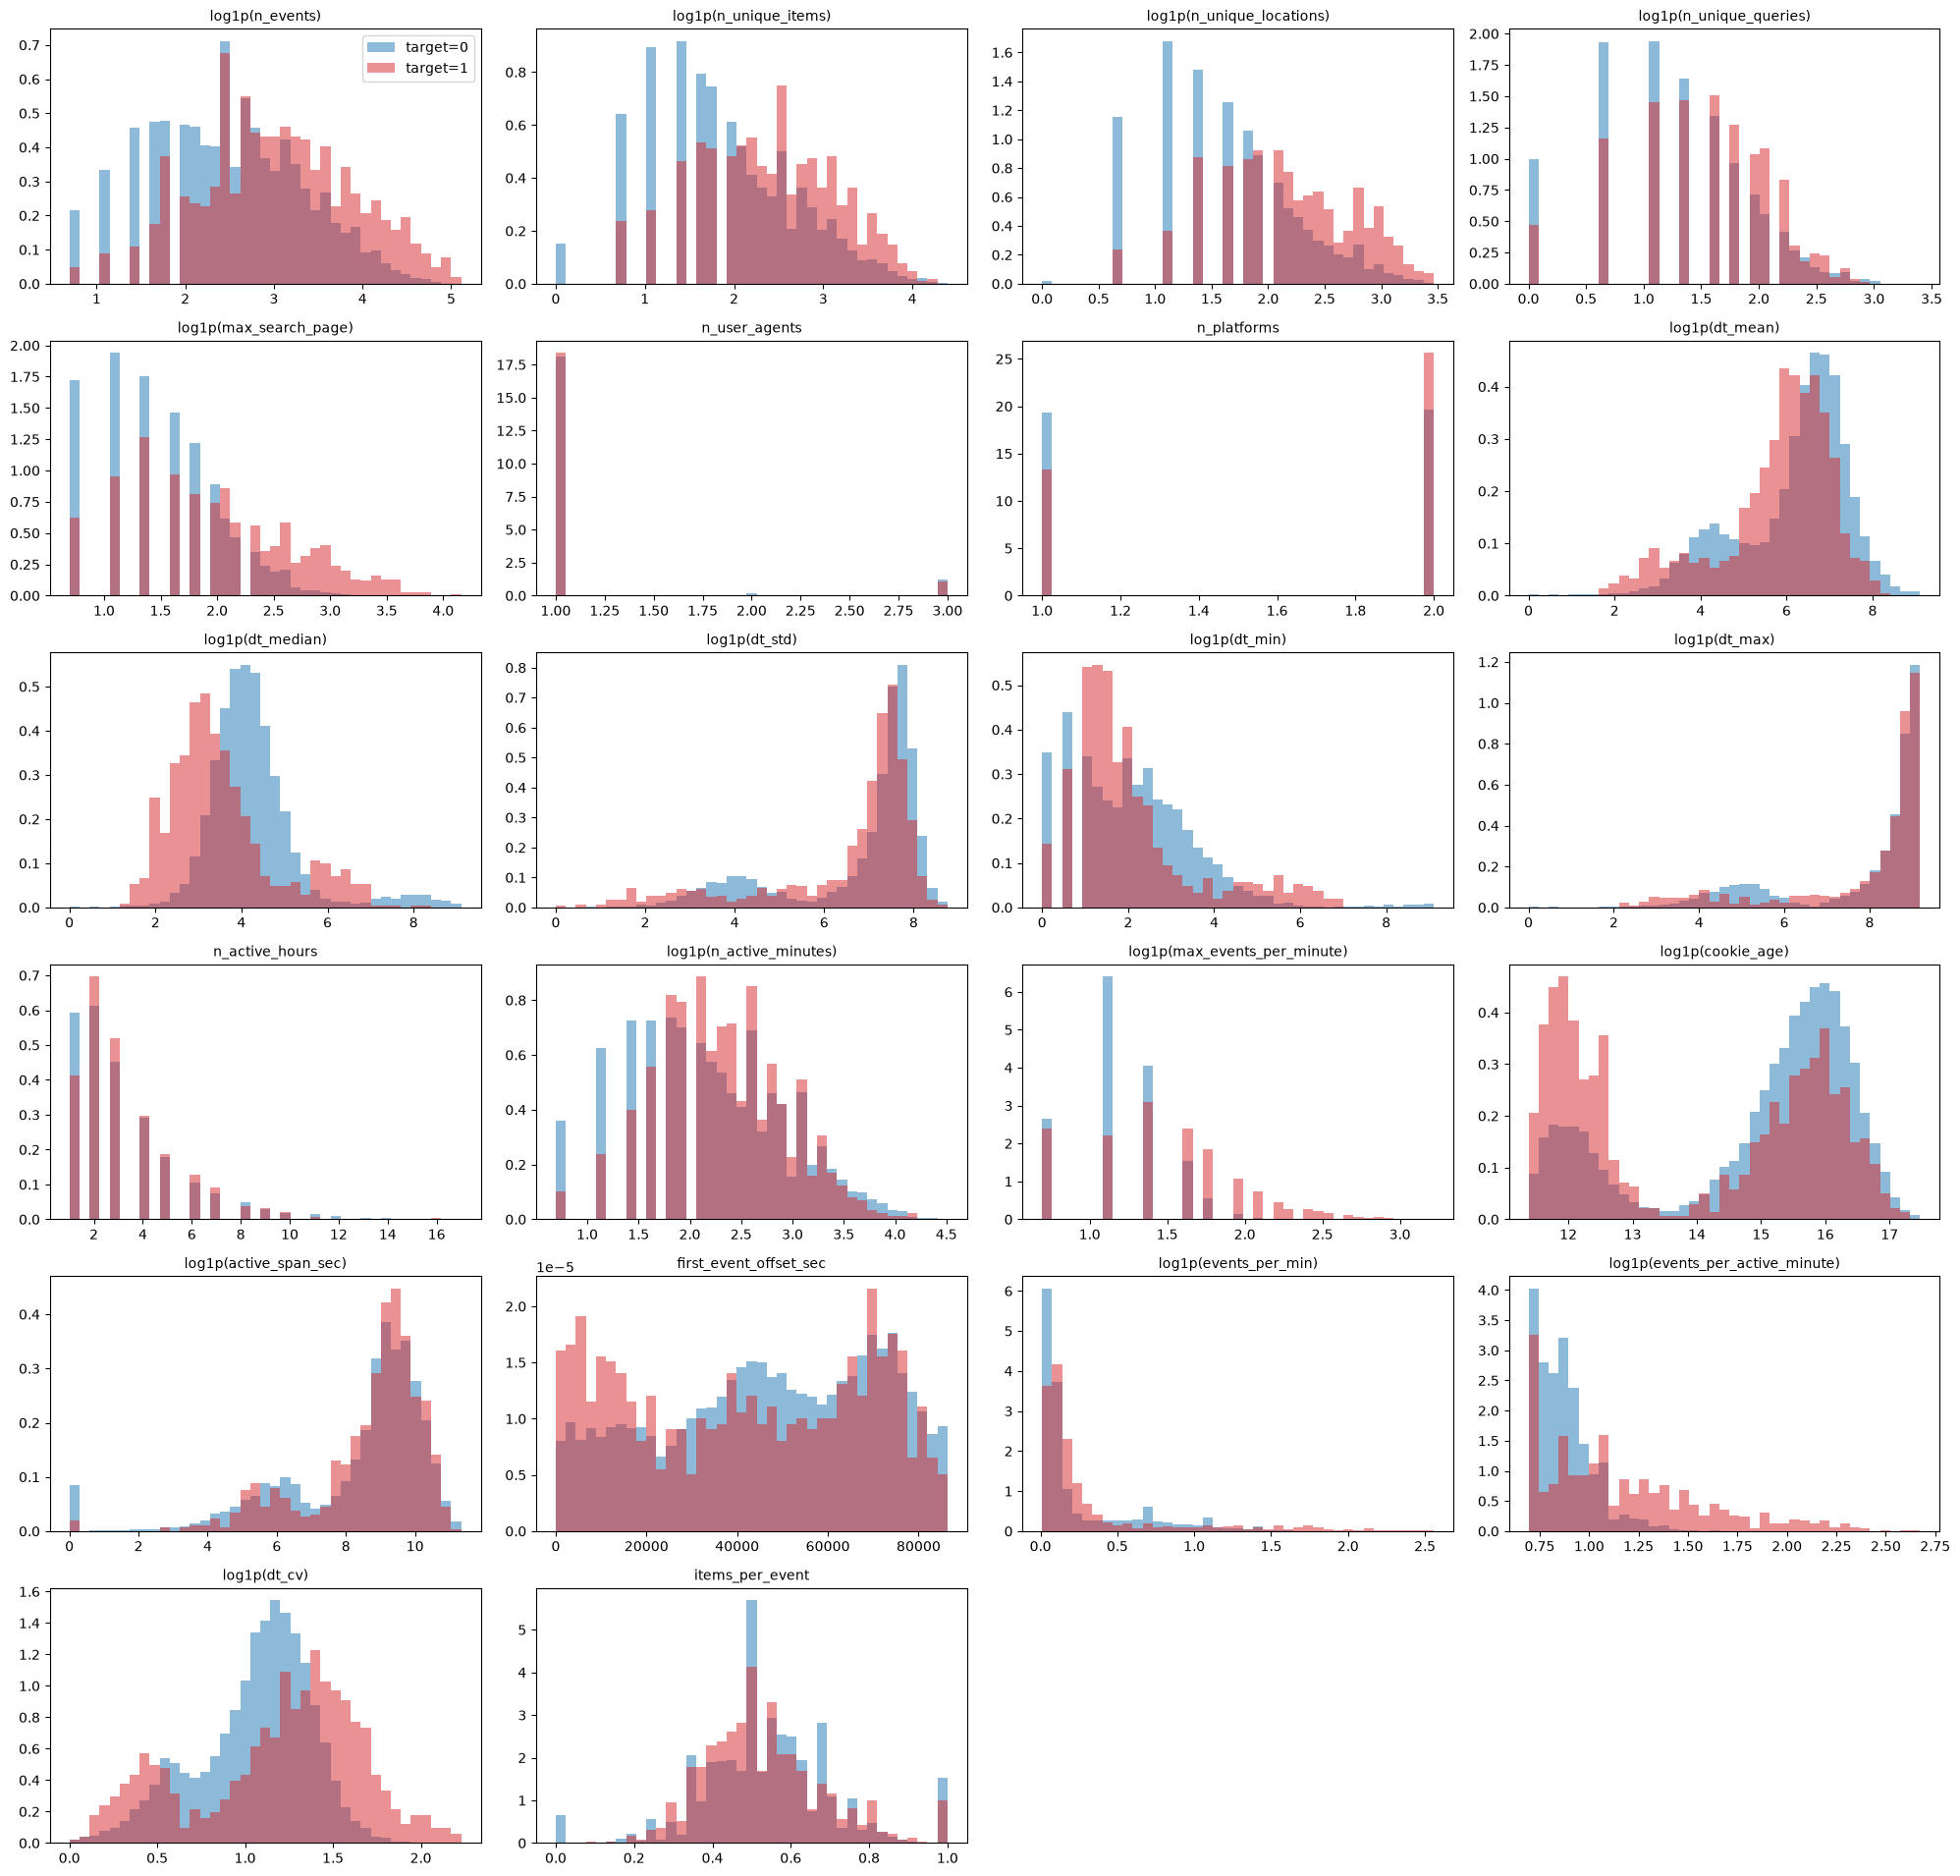

In [447]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df_plot = ev_train

exclude = ["cookie_id", "cookie_created_at", "window_start_ts", "window_end_ts", "target", "ua_marker"]
num_cols = [c for c in df_plot.select_dtypes("number").columns if c not in exclude]

log_cols = {"n_events", "n_unique_items", "n_unique_locations","n_unique_queries", "max_search_page",
            "cookie_age", "active_span_sec", "events_per_min", "events_per_active_minute",
            "max_events_per_minute", "dt_mean", "dt_median", "dt_std", "dt_min", "dt_max",
            "n_active_minutes", "dt_cv"}

ncols = 4
nrows = int(np.ceil(len(num_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.2 * nrows))
axes = axes.ravel()

for ax, col in zip(axes, num_cols):
    x = df_plot[col].astype(float)
    use_log = col in log_cols and (x.dropna() >= 0).all()
    if use_log:
        x = np.log1p(x)

    bins = np.linspace(x.min(), x.max(), 40)
    for t, color in [(0, "tab:blue"), (1, "tab:red")]:
        ax.hist(x[df_plot["target"] == t].dropna(), bins=bins,
                density=True, alpha=0.5, color=color, label=f"target={t}")
    ax.set_title(f"log1p({col})" if use_log else col, fontsize=10)

for ax in axes[len(num_cols):]:
    ax.set_visible(False)
axes[0].legend()
plt.tight_layout()
plt.show()

Глазами наблюдаю разделение классов на следующих признаках:

n_events,

n_unique_items, n_unique_locations

n_unique_queries, 

max_search_page, 

dt_median, dt_min, dt_cv

n_active_minutes (под вопросом, на самом деле), 

max_events_per_minute, 

cookie_age, 

first_event_offset (под вопросом тоже), 

events_per_active_minute

In [448]:
df_plot.groupby("ua_marker")["target"].agg(n="size", bot_rate="mean").sort_values("n", ascending=False)

,n,bot_rate
ua_marker,,
none,10605,0.073550
headlesschrome,286,0.262238
python,58,0.189655
go-http-client,42,0.166667
scrapy,35,0.257143
node-fetch,33,0.272727
curl,32,0.250000


Кажется, получился не очень сильный признак, но пусть будет

In [449]:
columns_good = ['n_events', 'n_unique_items', 'n_unique_queries', 'n_unique_locations', 'ua_marker', 'max_search_page', 
           'dt_median', 'dt_min', 'dt_cv', 'max_events_per_minute', 'cookie_age', 'events_per_active_minute']

Можно еще другие фичи придумать, например доля показов контактов от общего количества событий, доля показов капчи от общего количества событий. Доля непустых поинтеров при событиях на web/desktop платформе (для мобилок, насколько я знаю, этот параметр оставляют пустым, а вот для десктопа он должен заполняться). В общем, есть простор подумать и можно еще долго покопаться, но предлагаю перейти к бейзлайну и модели...

---
# Бейзлайн


In [450]:
X_tr_full = ev_train[columns_good]
X_te_full = ev_test[columns_good]
y = ev_train["target"].values


feat_cols = [c for c in X_tr_full.columns if c != "cookie_id"] #не будем обучать модель на куки айди))
X, Xte = X_tr_full[feat_cols], X_te_full[feat_cols]

На графиках выше видно, что на некоторых фичах есть разделение по классам. В качестве бейзлайна можем взять просто одиночный числовой признак

In [451]:
single = {c: max(precision_at_recall(y, X[c].fillna(-1e9)),
                 precision_at_recall(y, -X[c].fillna(1e9)))
          for c in X.select_dtypes("number").columns}
print(pd.Series(single).sort_values(ascending=False).head(10))

dt_median                   0.150782
events_per_active_minute    0.136669
n_unique_locations          0.134400
max_events_per_minute       0.130480
n_unique_items              0.120022
max_search_page             0.117690
n_events                    0.112424
cookie_age                  0.102219
n_unique_queries            0.100690
dt_min                      0.099890
dtype: float64


## Модель

В качестве модели выбран градиентный бустинг над деревьями — LightGBM (open-source, запускается локально).
параметры почти все дефолтные, добавила небольшую регуляризацию

## Валидация

Тестовая выборка лежит позже обучающей по времени, поэтому валидация тоже временная. Модель обучается на ранних окнах и проверяется на более поздних (`window_start_ts >= 2026-04-17`), поскольку 
- поведение сервисов сбора данных меняется со временем: появляются новые скрейперы, меняются задержки, ua и проч возможные параметры поведения, поэтому не можем перешать события во времени
-  куки в один и тот же день могут быть похожи друг на друга. При случайном сплите такие куки попадают и в обучение, и в валидацию, и метрика завышается.

Качество считается официальной функцией precision_at_recall




In [452]:
cats = pd.concat([X["ua_marker"], Xte["ua_marker"]]).dropna().unique()
X["ua_marker"] = pd.Categorical(X["ua_marker"], categories=cats)
Xte["ua_marker"] = pd.Categorical(Xte["ua_marker"], categories=cats)

params = dict(n_estimators=3000, reg_lambda=1.0, random_state=RANDOM_SEED, verbose=-1)

is_valid = ev_train.window_start_ts.ge('2026-04-17').values

model = lgb.LGBMClassifier(**params)
model.fit(X.loc[~is_valid], y[~is_valid],
          eval_set=[(X.loc[is_valid], y[is_valid])],
          eval_metric="average_precision",
          callbacks=[lgb.early_stopping(200, verbose=False)])
p_va = model.predict_proba(X.loc[is_valid])[:, 1]

print('P@R0.7 на валидации:', round(precision_at_recall(y[is_valid], p_va), 4))
print('R@FPR1% на валидации:', round(recall_at_fpr(y[is_valid], p_va), 4))
print('число деревьев:', model.best_iteration_)

/Users/clavinlig/Documents/bot_detection_challenge/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


P@R0.7 на валидации: 0.35
R@FPR1% на валидации: 0.4062
число деревьев: 32


In [453]:
final = lgb.LGBMClassifier(**{**params, "n_estimators": model.best_iteration_})
final.fit(X, y)

sub = pd.DataFrame({
    'cookie_id': ev_test.cookie_id,
    'score': final.predict_proba(Xte)[:, 1],
})
assert len(sub) == len(test) and sub.score.between(0, 1).all()
assert (sub.cookie_id.values == test.cookie_id.values).all()
sub.to_csv('submission.csv', index=False)
sub.head()

,cookie_id,score
0,ck_315fb710a0e371e7,0.017326
1,ck_a76ee3b3e3e522fd,0.182321
2,ck_94c9a4d382689e82,0.037759
3,ck_8eaf9509ad9462a0,0.016647
4,ck_9a88a5a989cb5bc6,0.016492


Получили P@R0.7: 0.35 на валидации

Дальше есть следующие варианты развития событий
- попробовать добавить новых фичей и опробовать с той же моделью с те ми же гиперпараметрами и посмотреть, получится ли что-то получше
- заняться подбором оптимальных гиперпараметров